In [22]:
no_of_threads = "12"

import os
os.environ["VECLIB_MAXIMUM_THREADS"] = no_of_threads
os.environ["OMP_NUM_THREADS"] = no_of_threads


In [23]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


In [24]:
B=32 #Batchsize

In [25]:


import torch
from torch import linalg as LA
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import time
import statistics
from typing import Tuple
from typing_extensions import Annotated
import transformers
import psutil

from transformers import AutoModelForCausalLM, AutoTokenizer
import json
import platform
import subprocess
import time
import re

In [26]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
REVISION = "989aa7980e4cf806f80c7fef2b1adb7bc71aa306"   

#model_hf = AutoModelForCausalLM.from_pretrained(
#    MODEL_ID, revision=REVISION, dtype=torch.float32, device_map="cpu"
#)

model_hf = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, dtype=torch.float32
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

In [27]:


def extract_letter(text):
   
    for pat in (r"answer is\s*:?\s*\(?([A-E1-5])\b",  
                r"^\s*\(?([A-E1-5])[\).:]",           
                r"\b([A-E1-5])[\).]"):                
        m = re.search(pat, text, re.I | re.M)
        if m:
            return m.group(1).upper()
    return None

tokenizer.padding_side = "left"
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def time_counter(no_of_threads: int, model, tokenizer, prompts: list, results: list,
                 answer_keys: list = None, max_new_tokens: int = 128,
                 batch_size: int = B, repeats: int = 3):

    torch.set_num_threads(int(no_of_threads))
    print("threads:", torch.get_num_threads())
    time.sleep(2)
    proc = psutil.Process(os.getpid())

    for start in range(0, len(prompts), batch_size):
        ids = list(range(start, min(start + batch_size, len(prompts))))
        texts = [tokenizer.apply_chat_template([{"role": "user", "content": prompts[i]}],
                                               tokenize=False, add_generation_prompt=True)
                 for i in ids]
        
        
        model_inputs = tokenizer(texts, return_tensors="pt", padding=True).to(model.device)
        print(model_inputs["input_ids"][:, :5])
        print(tokenizer.pad_token_id)
        input_len = model_inputs["input_ids"].shape[1]

        with torch.inference_mode():
            
            model.generate(**model_inputs, max_new_tokens=max_new_tokens, do_sample=False,
                               pad_token_id=tokenizer.pad_token_id)

            n_lst = []
            for i in range(repeats):
                start_time = time.perf_counter()
                out_put_ids = model.generate(**model_inputs, max_new_tokens=max_new_tokens, do_sample=False,
                               pad_token_id=tokenizer.pad_token_id)
                end_time = time.perf_counter()
                n_lst.append(end_time - start_time)

        mean = statistics.mean(n_lst)
        stndev = statistics.stdev(n_lst) if len(n_lst) > 1 else 0.0
        mem_gb = proc.memory_info().rss / 1e9
        gen = out_put_ids[:, input_len:]
        n_new = (gen != tokenizer.pad_token_id).sum(dim=1).tolist()
        for row, pid in enumerate(ids):
            answer = tokenizer.decode(gen[row], skip_special_tokens=True)
            letter = extract_letter(answer)
            n_dict = {
                'thread': torch.get_num_threads(),
                'batch_size': batch_size,
                'batch_start': start,
                'prompt_id': pid,
                'batch_mean': mean,
                'batch_stdev': stndev,
                'input_tokens': input_len,
                'new_tokens': n_new[row],
                'mem_gb': mem_gb,
                'answer': answer,
                'pred': letter,
            }
            if answer_keys is not None:
                n_dict['key'] = answer_keys[pid]
                n_dict['correct'] = (letter == answer_keys[pid])
            results.append(n_dict)


        

In [28]:
results = []

# 32 questions, 8 each of A/B/C/D. Built by select_prompts.py
with open("prompts_arc32_balanced.json") as f:
    data = json.load(f)
prompts, answer_keys = data["prompts"], data["answer_keys"]
print(len(prompts), len(answer_keys))   # 32 32

32 32


In [29]:


run_name = datetime.now().strftime(f"openblas_32p_batch{B}_%Y-%m-%d_%H-%M")  
os.makedirs("results", exist_ok=True)
csv_file = f"results/{run_name}.csv"
print("saving to", csv_file)

results = []

for t in range(1,13):
    time_counter(t, model_hf, tokenizer, prompts, results, answer_keys=answer_keys)
    pd.DataFrame(results).to_csv(csv_file, index=False)
    print("saved after", t, "threads,", len(results), "rows")
    

saving to results/openblas_32p_batch32_2026-11-04_09-13.csv
threads: 1
tensor([[151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 151643, 151643, 151643],
        [151643, 151643, 1516

In [30]:
results

[{'thread': 1,
  'batch_size': 32,
  'batch_start': 0,
  'prompt_id': 0,
  'batch_mean': 282.90061548600596,
  'batch_stdev': 0.5188757419639578,
  'input_tokens': 172,
  'new_tokens': 128,
  'mem_gb': 15.220146176,
  'answer': 'The correct answer is D. The type of environment in which the organisms lived.\n\nExplanation: When examining fossils, one can observe various features such as bone structure, wear patterns, and other physical characteristics to infer about the environment in which the organisms lived. For example:\n\n- **Bone Structure**: Different types of bones (e.g., long bones vs. short bones) suggest different lifestyles or habitats.\n- **Wear Patterns**: The way bones have been worn down over time can indicate whether an animal was active during certain times of day or season.\n- **Fossil Formation Conditions**: Fossils often form in specific environments like water bodies,',
  'pred': 'D',
  'key': 'D',
  'correct': True},
 {'thread': 1,
  'batch_size': 32,
  'batch_sta

In [31]:
print(torch.__config__.show())

PyTorch built with:
  - GCC 4.2
  - C++ Version: 202002
  - clang 21.1.8
  - OpenMP 202011
  - LAPACK is enabled (usually provided by MKL)
  - NNPACK is enabled
  - CPU capability usage: DEFAULT
  - Build settings: BLAS_INFO=open, BUILD_TYPE=Release, COMMIT_SHA=Unknown, CUDA_FLAGS= -DLIBCUDACXX_ENABLE_SIMPLIFIED_COMPLEX_OPERATIONS -Xfatbin -compress-all  -Wno-deprecated-gpu-targets --expt-extended-lambda -DCUB_WRAPPED_NAMESPACE=at_cuda_detail -DDISABLE_CUSPARSE_DEPRECATED -DCUDA_HAS_FP16=1 -D__CUDA_NO_HALF_OPERATORS__ -D__CUDA_NO_HALF_CONVERSIONS__ -D__CUDA_NO_HALF2_OPERATORS__ -D__CUDA_NO_BFLOAT16_CONVERSIONS__ -DC10_NODEPRECATED, CXX_COMPILER=/Users/runner/miniforge3/conda-bld/libtorch_1791585336308/_build_env/bin/arm64-apple-darwin20.0.0-clang++, CXX_FLAGS=-ftree-vectorize -fPIC -fstack-protector-strong -O2 -pipe -stdlib=libc++  -fmessage-length=0 -isystem /Users/runner/miniforge3/conda-bld/libtorch_1791585336308/_h_env_placehold_placehold_placehold_placehold_placehold_placehold_pla

In [32]:
df = pd.DataFrame(results)
per_batch = df.drop_duplicates(["thread", "batch_start"])        
total = per_batch.groupby("thread")["batch_mean"].sum()          
t1 = total.loc[1]

n_res = []
for n, t in total.items():
    speedup = t1 / t
    n_res.append({
        "threads": n,
        "mean": t,
        "speedup": speedup,
        "efficiency": speedup / n * 100,
        "serial_fraction": ((n / speedup - 1) / (n - 1)) * 100 if n > 1 else None,
    })

In [33]:
n_res

[{'threads': 1,
  'mean': 282.90061548600596,
  'speedup': np.float64(1.0),
  'efficiency': np.float64(100.0),
  'serial_fraction': None},
 {'threads': 2,
  'mean': 151.66063177767987,
  'speedup': np.float64(1.8653530067098196),
  'efficiency': np.float64(93.26765033549098),
  'serial_fraction': np.float64(7.218311644275621)},
 {'threads': 3,
  'mean': 149.56693248598216,
  'speedup': np.float64(1.8914649834950663),
  'efficiency': np.float64(63.048832783168876),
  'serial_fraction': np.float64(29.3036092705394)},
 {'threads': 4,
  'mean': 149.1334047499889,
  'speedup': np.float64(1.8969634332446703),
  'efficiency': np.float64(47.424085831116756),
  'serial_fraction': np.float64(36.95443869043872)},
 {'threads': 5,
  'mean': 149.80866368029578,
  'speedup': np.float64(1.8884129164234422),
  'efficiency': np.float64(37.768258328468846),
  'serial_fraction': np.float64(41.19315029720493)},
 {'threads': 6,
  'mean': 148.86456154166567,
  'speedup': np.float64(1.9003892703289558),
  'ef

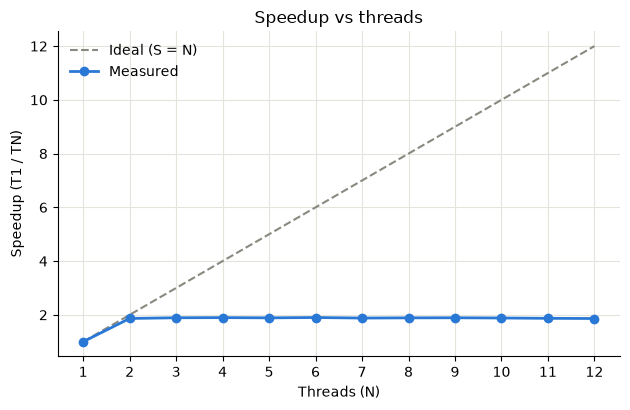

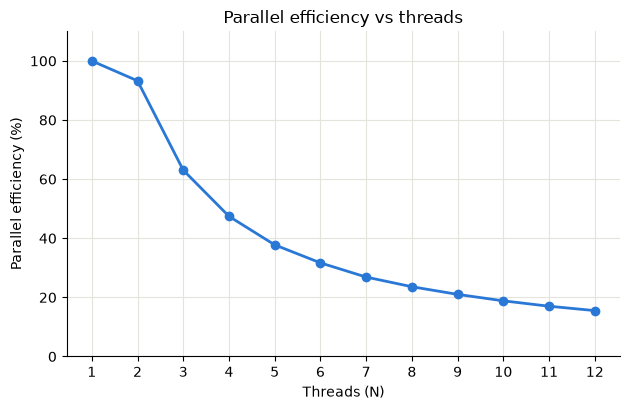

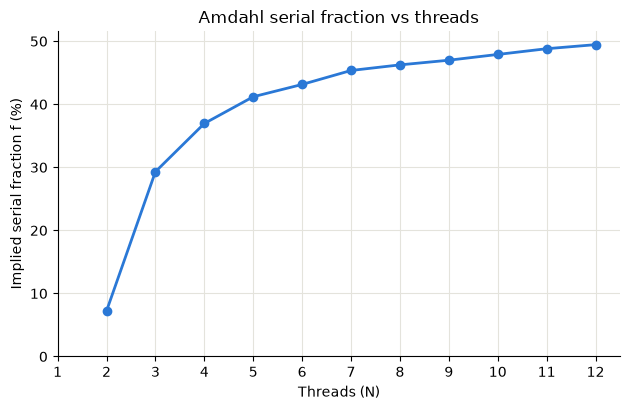

In [34]:


threads = [r["threads"] for r in n_res]
speedup = [r["speedup"] for r in n_res]
efficiency = [r["efficiency"] for r in n_res]

f_threads = [n for n in threads if n > 1]
serial = [((n / s) - 1) / (n - 1) * 100 for n, s in zip(threads, speedup) if n > 1]

BLUE, GREY = "#2a78d6", "#8a8980"

def tidy(ax, ylabel, title):
    ax.set_xlabel("Threads (N)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(threads)
    ax.grid(True, color="#e4e3dc")
    ax.spines[["top", "right"]].set_visible(False)

# 1. Speedup vs ideal
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, threads, "--", color=GREY, label="Ideal (S = N)")
ax.plot(threads, speedup, "o-", color=BLUE, linewidth=2, label="Measured")
tidy(ax, "Speedup (T1 / TN)", "Speedup vs threads")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()

# 2. Efficiency
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, efficiency, "o-", color=BLUE, linewidth=2)
ax.set_ylim(0, 110)
tidy(ax, "Parallel efficiency (%)", "Parallel efficiency vs threads")
fig.tight_layout(); plt.show()

# 3. Serial fraction
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(f_threads, serial, "o-", color=BLUE, linewidth=2)
ax.set_ylim(bottom=0)
tidy(ax, "Implied serial fraction f (%)", "Amdahl serial fraction vs threads")
fig.tight_layout(); plt.show()